# 02 · 从零实现一个迷你 YOLOv1

> 这一本会真正训练一个 YOLO。不是调用 `model.fit()`，而是自己写：
> **网格、目标分配、YOLO loss、解码、NMS、评估**。
>
> 为了在几分钟内跑完，我们做了一个“迷你版”：
>
> - 输入 `112×112`，网格 `7×7`，每个格子 2 个预测框，3 个类别。
> - 骨干网络是 4 个 stride=2 的卷积块，不追求精度，只保留 YOLO 的核心结构。
> - 数据是程序生成的彩色几何图形，不需要下载数据集。
> - 损失用简化的 MSE（原版 YOLOv1 也是 MSE 家族，但细节更多）。
>
> 训练完你会看到一个能同时检测多个彩色图形的模型。它的 mAP 不会很高，但**每一个张量、每一个 loss 项你都能讲清楚**。

## 0. 先看全景

```text
图像 [3,112,112]
   │
   ├─ Conv 3×3 s2, 32   → [32,56,56]
   ├─ Conv 3×3 s2, 64   → [64,28,28]
   ├─ Conv 3×3 s2,128   → [128,14,14]
   ├─ Conv 3×3 s2,256   → [256,7,7]
   ├─ Conv 3×3,   256   → [256,7,7]
   └─ Conv 1×1, 2×(5+3)=16
                          │
                          ▼
                 [B,16,7,7] → reshape → [B,7,7,2,8]
                                             │  │  │
                                             │  │  └─ 3 个类别概率
                                             │  └──── 1 个 objectness
                                             └─────── 4 个框参数 (tx,ty,tw,th)
```

关键点：

- **tx, ty 是相对于所在格子的偏移**，不是全图坐标。这是 YOLO 能泛化到不同位置的关键。
- `tw, th` 是归一化宽高（相对于整张图）。
- 每个格子有 2 个框，但训练时只有与 GT 的 IoU 最大的那个框负责回归，另一个只学“我是背景”。

In [1]:
import math
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import rcParams
from PIL import Image, ImageDraw

import torch
import torch.nn as nn

rcParams.update({
    "figure.dpi": 110,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

SEED = 42
IMG_SIZE = 112
GRID = 7
CELL = IMG_SIZE // GRID
NUM_CLASSES = 3
BOXES_PER_CELL = 2
CLASS_NAMES = ["red", "green", "blue"]
COLORS = [(225, 55, 55), (55, 205, 95), (65, 125, 235)]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# CPU 用户可以把 FAST 改成 True：数据更少、训练更短
FAST = False
TRAIN_SIZE = 800 if not FAST else 240
VAL_SIZE = 120 if not FAST else 48
EPOCHS = 30 if not FAST else 8
BATCH_SIZE = 64

ROOT = Path.cwd()
CHECKPOINT_DIR = ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
torch.manual_seed(SEED)
print("device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print(f"train={TRAIN_SIZE}, val={VAL_SIZE}, epochs={EPOCHS}, batch={BATCH_SIZE}")

device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
train=800, val=120, epochs=30, batch=64


## 1. 合成数据：彩色图形检测

每个样本随机放 1–2 个图形（圆或矩形），颜色决定类别：

| 类别 id | 名称 | 颜色 |
|---|---|---|
| 0 | red | 红 |
| 1 | green | 绿 |
| 2 | blue | 蓝 |

标签使用 YOLO 格式：`(cx, cy, w, h)`，全部除以 `112` 归一化到 `[0,1]`。

数据是“简单”的，但已经包含检测的核心难点：**多物体、不同位置、不同大小、类别与外观对应**。

In [2]:
def make_sample(rng):
    img = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    img[:] = rng.integers(10, 28, size=3)
    pil = Image.fromarray(img)
    draw = ImageDraw.Draw(pil)

    n = int(rng.integers(1, 3))  # 1 或 2 个物体
    cells = rng.choice(GRID * GRID, size=n, replace=False)
    boxes, labels = [], []

    for cell in cells:
        row, col = divmod(int(cell), GRID)
        w = float(rng.uniform(24, 44))
        h = float(rng.uniform(24, 44))
        cx = (col + rng.uniform(0.25, 0.75)) * CELL
        cy = (row + rng.uniform(0.25, 0.75)) * CELL
        cx = float(np.clip(cx, w / 2 + 1, IMG_SIZE - w / 2 - 1))
        cy = float(np.clip(cy, h / 2 + 1, IMG_SIZE - h / 2 - 1))

        cls = int(rng.integers(NUM_CLASSES))
        color = np.array(COLORS[cls]) + rng.integers(-18, 19, size=3)
        color = tuple(int(v) for v in np.clip(color, 0, 255))

        x0, y0, x1, y1 = cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2
        if rng.random() < 0.5:
            draw.ellipse([x0, y0, x1, y1], fill=color, outline=(245, 245, 245), width=1)
        else:
            draw.rectangle([x0, y0, x1, y1], fill=color, outline=(245, 245, 245), width=1)

        boxes.append([cx / IMG_SIZE, cy / IMG_SIZE, w / IMG_SIZE, h / IMG_SIZE])
        labels.append(cls)

    img = np.asarray(pil).astype(np.float32) / 255.0
    img = np.clip(img + rng.normal(0, 0.018, img.shape), 0, 1).astype(np.float32)
    return img, np.array(boxes, dtype=np.float32), np.array(labels, dtype=np.int64)


def make_dataset(n, seed):
    r = np.random.default_rng(seed)
    imgs, all_boxes, all_labels = [], [], []
    for _ in range(n):
        im, bx, lb = make_sample(r)
        # 两个 GT 的中心可能落到同一个格子；YOLOv1 一个格子只能负责一个物体，丢掉重复的
        seen, keep = set(), []
        for k, (cx, cy, w, h) in enumerate(bx):
            cell = (min(int(cy * GRID), GRID - 1), min(int(cx * GRID), GRID - 1))
            if cell not in seen:
                seen.add(cell)
                keep.append(k)
        imgs.append(im)
        all_boxes.append(bx[keep])
        all_labels.append(lb[keep])
    images = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).contiguous()
    return images, all_boxes, all_labels


train_images, train_boxes, train_labels = make_dataset(TRAIN_SIZE, seed=1)
val_images, val_boxes, val_labels = make_dataset(VAL_SIZE, seed=2)

print("train images:", tuple(train_images.shape))
print("val images  :", tuple(val_images.shape))
print("train objects:", sum(len(b) for b in train_boxes))
print("第 0 张图的标签 (cx,cy,w,h):\n", np.round(train_boxes[0], 4), train_labels[0])

train images: (800, 3, 112, 112)
val images  : (120, 3, 112, 112)
train objects: 1189
第 0 张图的标签 (cx,cy,w,h):
 [[0.2377 0.1539 0.27   0.2899]] [2]


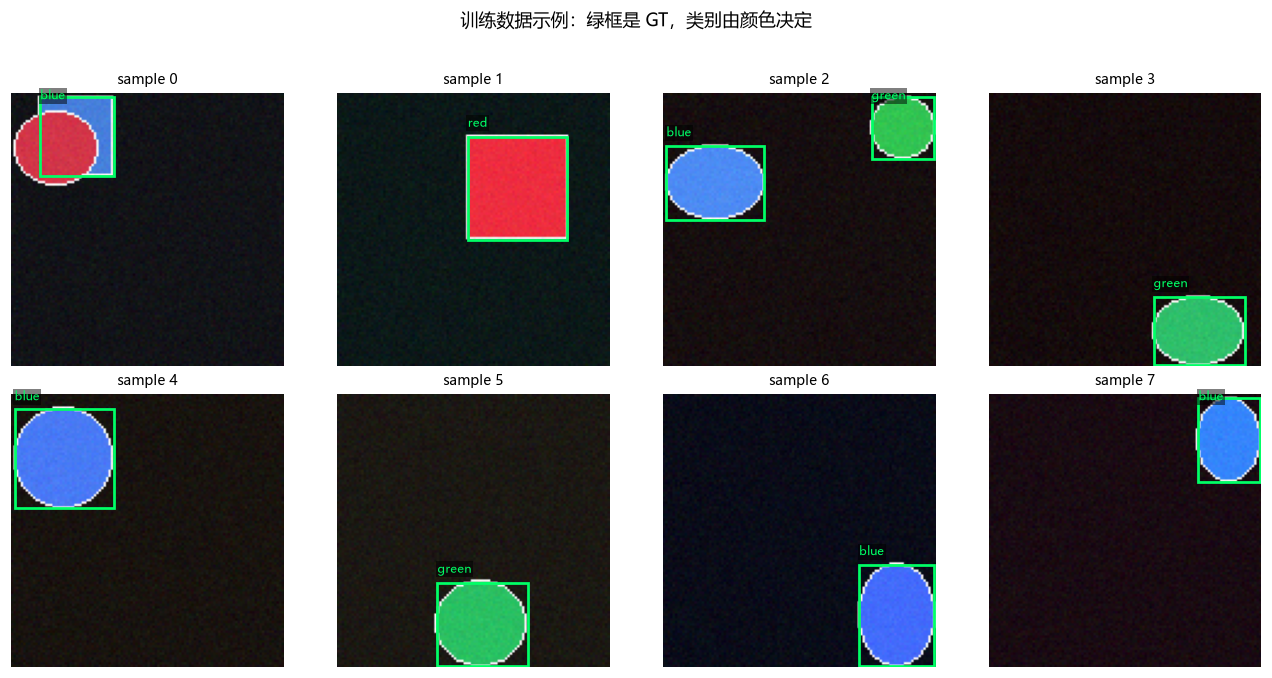

In [3]:
def draw_gt(ax, img, boxes, labels, color="#00ff66"):
    ax.imshow(np.clip(img.permute(1, 2, 0).numpy(), 0, 1))
    for box, label in zip(boxes, labels):
        cx, cy, w, h = box * IMG_SIZE
        x1, y1 = cx - w / 2, cy - h / 2
        ax.add_patch(patches.Rectangle((x1, y1), w, h, fill=False,
                                       edgecolor=color, linewidth=1.8))
        ax.text(x1, max(y1 - 4, 2), CLASS_NAMES[label], color=color, fontsize=8,
                bbox=dict(facecolor="black", alpha=0.5, pad=1, edgecolor="none"))
    ax.axis("off")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.ravel(), range(8)):
    draw_gt(ax, train_images[i], train_boxes[i], train_labels[i])
    ax.set_title(f"sample {i}", fontsize=9)
plt.suptitle("训练数据示例：绿框是 GT，类别由颜色决定", y=1.02)
plt.tight_layout()
plt.show()

### 1.1 为什么用合成数据？

- **零下载**：打开 notebook 就能跑。
- **标签绝对准确**：方便把注意力放在模型和 loss 上。
- **可控**：你可以马上改类别数、图形大小、每图物体数，观察对训练的影响。

代价是它太简单，不能代表真实场景。学完原理后，换到 COCO/VOC 或自己的数据，代码结构是一样的。

## 2. 模型：一个全卷积的迷你 YOLO

原版 YOLOv1 是 24 层卷积 + 2 层全连接，输入 `448×448`，输出 `7×7×30`。这里我们用全卷积结构，避免全连接层对输入尺寸的硬编码，同时保留“**下采样到 7×7，每个格子输出 2 个框**”的设计。

输出张量的最后一维是 `5 + C = 8`：

| 下标 | 含义 | 激活 |
|---|---|---|
| 0,1 | `tx, ty`：格子内偏移 | sigmoid → `[0,1]` |
| 2,3 | `tw, th`：归一化宽高 | sigmoid → `[0,1]` |
| 4 | `objectness` | sigmoid |
| 5:8 | 3 个类别概率 | sigmoid（多标签形式） |

In [4]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.SiLU(inplace=True),
    )


class TinyYOLO(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, boxes_per_cell=BOXES_PER_CELL):
        super().__init__()
        self.num_classes = num_classes
        self.boxes_per_cell = boxes_per_cell
        self.backbone = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            nn.Conv2d(256, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.SiLU(inplace=True),
        )
        self.head = nn.Conv2d(256, boxes_per_cell * (5 + num_classes), 1)

    def forward(self, x):
        x = self.backbone(x)
        x = self.head(x)
        b, _, s, _ = x.shape
        x = x.view(b, self.boxes_per_cell, 5 + self.num_classes, s, s)
        x = x.permute(0, 3, 4, 1, 2)  # [B, S, S, B, 5+C]

        xy = torch.sigmoid(x[..., 0:2])
        wh = torch.sigmoid(x[..., 2:4])
        obj = torch.sigmoid(x[..., 4:5])
        cls = torch.sigmoid(x[..., 5:])
        return torch.cat([xy, wh, obj, cls], dim=-1)


model = TinyYOLO().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"参数量: {n_params:,} ({n_params / 1e6:.2f}M)")

with torch.no_grad():
    dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    out = model(dummy)
print("输入:", tuple(dummy.shape))
print("输出:", tuple(out.shape), "= [B, S, S, B_boxes, 5+C]")

参数量: 983,344 (0.98M)
输入: (1, 3, 112, 112)
输出: (1, 7, 7, 2, 8) = [B, S, S, B_boxes, 5+C]


## 3. 目标分配：哪个格子、哪个框负责哪个物体？

这是 YOLO 训练最核心、也最容易写错的一步。规则：

1. 取 GT 的中心点 `(cx, cy)`，算出它落在哪个格子 `(row, col)`。
2. 这个格子里的 `B=2` 个预测框，谁和 GT 的 IoU 大，谁负责这个 GT。
3. 负责的框：
   - `objectness target = 1`
   - 框 target = `(cx*S - col, cy*S - row, w, h)` ← **注意前两个是格子内偏移**
   - 类别 target = 对应类别的 one-hot
4. 同格子的另一个框：`objectness target = 0`，不参与框回归和分类 loss。
5. 没有物体的格子：所有框 `objectness target = 0`。

> 第 3 步的偏移写法是 YOLO 的关键。如果直接让网络回归全图 `cx,cy`，模型会倾向于记住物体的绝对位置；改成“相对于格子左上角的偏移”，每个格子只需要学局部模式，泛化会好很多。

In [7]:
def encode_targets(boxes_list, labels_list, preds):
    '''把 GT 编码成和 preds 同形状的 target: [B,S,S,B_boxes,5+C]。'''
    b, s = preds.shape[0], preds.shape[1]
    target = torch.zeros((b, s, s, BOXES_PER_CELL, 5 + NUM_CLASSES), device=preds.device)

    for bi, (boxes, labels) in enumerate(zip(boxes_list, labels_list)):
        for box, label in zip(boxes, labels):
            cx, cy, w, h = [float(v) for v in box]
            col = min(int(cx * s), s - 1)
            row = min(int(cy * s), s - 1)

            # 用当前预测解码出的绝对框，和 GT 算 IoU，选负责的 predictor
            pb = preds[bi, row, col, :, :4].detach()
            abs_xy = torch.stack([(pb[:, 0] + col) / s, (pb[:, 1] + row) / s], dim=-1)
            pbox = torch.cat([abs_xy - pb[:, 2:] / 2, abs_xy + pb[:, 2:] / 2], dim=-1)
            gbox = torch.tensor(
                [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2],
                device=preds.device,
            )
            lt = torch.maximum(pbox[:, :2], gbox[:2])
            rb = torch.minimum(pbox[:, 2:], gbox[2:])
            inter = (rb - lt).clamp(min=0).prod(-1)
            area_p = (pbox[:, 2] - pbox[:, 0]).clamp(min=0) * (pbox[:, 3] - pbox[:, 1]).clamp(min=0)
            area_g = (gbox[2] - gbox[0]).clamp(min=0) * (gbox[3] - gbox[1]).clamp(min=0)
            iou = inter / (area_p + area_g - inter + 1e-6)
            best = int(iou.argmax())

            target[bi, row, col, best, 0] = cx * s - col
            target[bi, row, col, best, 1] = cy * s - row
            target[bi, row, col, best, 2] = w
            target[bi, row, col, best, 3] = h
            target[bi, row, col, best, 4] = 1.0
            target[bi, row, col, best, 5 + int(label)] = 1.0

    return target

# 看一下第 0 张图的目标
with torch.no_grad():
    sample_pred = model(train_images[0:1].to(DEVICE))
sample_target = encode_targets([train_boxes[0]], [train_labels[0]], sample_pred)

obj_grid = sample_target[0, ..., 4].sum(-1).cpu()
print("objectness target 网格 (1 表示该格负责一个物体):")
print(obj_grid.numpy().astype(int))
print("\n被选中的格子/框:")
for row, col, b in zip(*torch.where(sample_target[0, ..., 4] > 0)):
    print(f"  row={int(row)}, col={int(col)}, predictor={int(b)}")
    print("  target (tx,ty,tw,th):", np.round(sample_target[0, row, col, b, :4].cpu().numpy(), 3))
    print("  class:", int(sample_target[0, row, col, b, 5:].argmax()))

objectness target 网格 (1 表示该格负责一个物体):
[[0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

被选中的格子/框:
  row=1, col=1, predictor=1
  target (tx,ty,tw,th): [0.664 0.077 0.27  0.29 ]
  class: 2


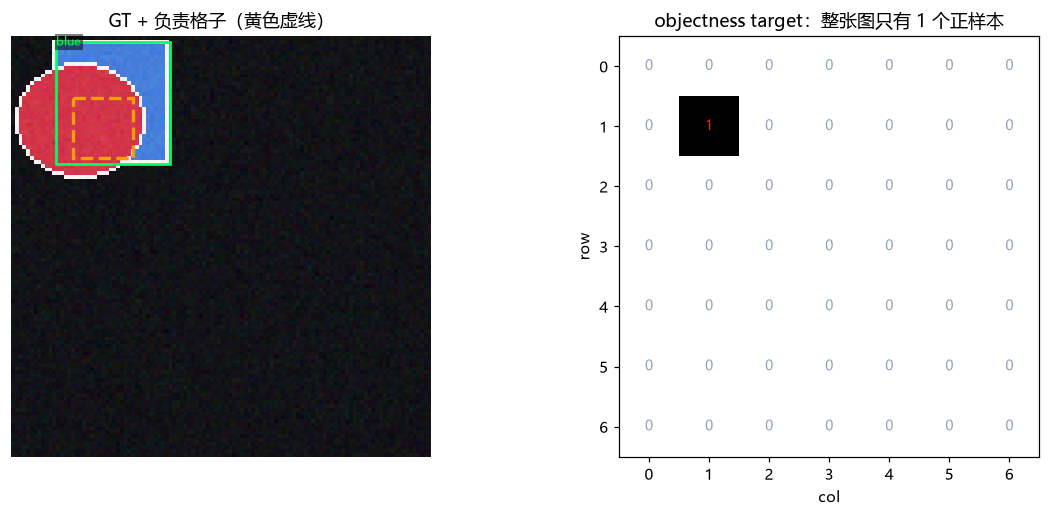

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

ax = axes[0]
draw_gt(ax, train_images[0], train_boxes[0], train_labels[0])
# 画出负责格子的边界
for row, col, b in zip(*torch.where(sample_target[0, ..., 4] > 0)):
    r, c = int(row), int(col)
    ax.add_patch(patches.Rectangle((c * CELL, r * CELL), CELL, CELL,
                                   fill=False, edgecolor="#f59e0b", lw=2.2, linestyle="--"))
ax.set_title("GT + 负责格子（黄色虚线）")

ax = axes[1]
ax.imshow(obj_grid.numpy(), cmap="Greys", vmin=0, vmax=1)
for r in range(GRID):
    for c in range(GRID):
        ax.text(c, r, int(obj_grid[r, c]), ha="center", va="center",
                color="#dc2626" if obj_grid[r, c] > 0 else "#94a3b8", fontsize=9)
ax.set_xticks(range(GRID))
ax.set_yticks(range(GRID))
ax.set_title("objectness target：整张图只有 1 个正样本")
ax.set_xlabel("col")
ax.set_ylabel("row")
plt.tight_layout()
plt.show()

## 4. YOLO loss：五项拆成三项

原版 YOLOv1 的损失可以拆成：

$$
L =
\lambda_{coord}\sum_{i,j}\mathbb{1}_{ij}^{obj}
\left[(x_i-\hat{x}_i)^2+(y_i-\hat{y}_i)^2\right]
+
\lambda_{coord}\sum_{i,j}\mathbb{1}_{ij}^{obj}
\left[(\sqrt{w_i}-\sqrt{\hat{w}_i})^2+(\sqrt{h_i}-\sqrt{\hat{h}_i})^2\right]
$$
$$
+
\sum_{i,j}\mathbb{1}_{ij}^{obj}(C_i-\hat{C}_i)^2
+
\lambda_{noobj}\sum_{i,j}\mathbb{1}_{ij}^{noobj}(C_i-\hat{C}_i)^2
+
\sum_{i,j}\mathbb{1}_{ij}^{obj}\sum_{c\in classes}(p_i(c)-\hat{p}_i(c))^2
$$

我们做了两点简化，但保留了最重要的结构：

- 宽高直接回归 `w,h`，不取平方根。
- 用两个 predictor 的 one-hot 选择，只对负责框算框损失和分类损失。

权重：`coord=5.0`（定位更重要），`noobj=0.5`（背景太多，压制一下）。

In [8]:
def yolo_loss(preds, target, coord=5.0, noobj=0.5):
    obj = target[..., 4]                  # [B,S,S,B]
    noobj_mask = 1.0 - obj

    xy_loss = ((preds[..., :2] - target[..., :2]) ** 2).sum(-1)
    wh_loss = ((preds[..., 2:4] - target[..., 2:4]) ** 2).sum(-1)
    box_loss = ((xy_loss + wh_loss) * obj).sum() / obj.sum().clamp(min=1)

    obj_loss = (((preds[..., 4] - obj) ** 2) * (obj + noobj * noobj_mask)).mean()

    cls_loss = (((preds[..., 5:] - target[..., 5:]) ** 2).sum(-1) * obj).sum() / obj.sum().clamp(min=1)

    total = coord * box_loss + obj_loss + cls_loss
    return total, box_loss.detach(), obj_loss.detach(), cls_loss.detach()

### 4.1 动手验证 loss 的尺度

在训练前，先对一张图算一次 loss，确认它不是 `nan`，并把三项分开打印。这样训练曲线异常时，你能判断是定位、objectness 还是分类出了问题。

In [9]:
model.eval()
with torch.no_grad():
    imgs = train_images[0:2].to(DEVICE)
    preds = model(imgs)
    target = encode_targets(train_boxes[0:2], train_labels[0:2], preds)
    total, bl, ol, cl = yolo_loss(preds, target)

print(f"total     : {total.item():.4f}")
print(f"box_loss  : {bl.item():.4f}")
print(f"obj_loss  : {ol.item():.4f}")
print(f"cls_loss  : {cl.item():.4f}")
print("正样本框数:", int(target[..., 4].sum()))
print("总预测框数:", target[..., 4].numel())

total     : 1.7349
box_loss  : 0.1699
obj_loss  : 0.1279
cls_loss  : 0.7573
正样本框数: 2
总预测框数: 196


## 5. 训练

训练循环本身很普通：

```text
for epoch:
    for batch:
        forward  -> preds
        encode targets
        compute loss
        backward
        optimizer.step()
```

唯一特别的是：每个 batch 都要**根据当前预测重新计算负责框**，所以 `encode_targets` 需要 `preds`。这让标签分配是动态的（类似现代 YOLO 的 dynamic assignment，虽然规则简单得多）。

数据增强只做随机水平翻转。翻转后 `cx -> 1 - cx`，`w,h` 不变。

In [10]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
history = []
start = time.time()

for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(len(train_images))
    epoch_loss = 0.0
    n_batches = 0

    for i in range(0, len(train_images), BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE].tolist()
        imgs = train_images[idx].clone()
        batch_boxes = [train_boxes[j].copy() for j in idx]
        batch_labels = [train_labels[j].copy() for j in idx]

        # 随机水平翻转
        flip = torch.rand(len(idx)) < 0.5
        imgs[flip] = torch.flip(imgs[flip], dims=[3])
        for k in torch.where(flip)[0].tolist():
            batch_boxes[k][:, 0] = 1.0 - batch_boxes[k][:, 0]

        imgs = imgs.to(DEVICE)
        with torch.no_grad():
            dummy_preds = model(imgs)
        target = encode_targets(batch_boxes, batch_labels, dummy_preds)

        preds = model(imgs)
        loss, bl, ol, cl = yolo_loss(preds, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    scheduler.step()
    avg = epoch_loss / n_batches
    history.append(avg)
    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:02d} | loss {avg:.4f} | {time.time() - start:.1f}s")

torch.save({"model": model.state_dict(), "config": {"num_classes": NUM_CLASSES,
                                                    "boxes_per_cell": BOXES_PER_CELL}},
           CHECKPOINT_DIR / "yolo1_tiny.pt")
print("训练完成，checkpoint 已保存到", CHECKPOINT_DIR / "yolo1_tiny.pt")

epoch 00 | loss 0.9053 | 6.2s
epoch 05 | loss 0.0898 | 19.6s
epoch 10 | loss 0.0505 | 32.9s
epoch 15 | loss 0.0313 | 46.2s
epoch 20 | loss 0.0238 | 60.5s
epoch 25 | loss 0.0219 | 73.3s
epoch 29 | loss 0.0205 | 84.3s
训练完成，checkpoint 已保存到 d:\Models\YOLO\checkpoints\yolo1_tiny.pt


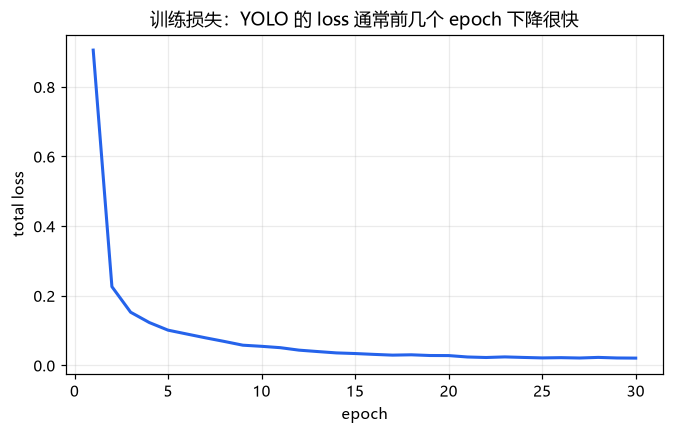

前 5 个 epoch: [0.9053 0.2258 0.1524 0.1227 0.1008]
后 5 个 epoch: [0.0219 0.0208 0.0226 0.0209 0.0205]


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(history) + 1), history, color="#2563eb", lw=2)
ax.set_xlabel("epoch")
ax.set_ylabel("total loss")
ax.set_title("训练损失：YOLO 的 loss 通常前几个 epoch 下降很快")
ax.grid(alpha=0.25)
plt.show()

print("前 5 个 epoch:", np.round(history[:5], 4))
print("后 5 个 epoch:", np.round(history[-5:], 4))

## 6. 解码：从 `[B,7,7,2,8]` 到画面上的框

网络输出的是“格子内偏移 + 宽高 + objectness + 类别”。推理时要反着做：

1. 对每个格子 `(row, col)`，把 `tx, ty` 还原成绝对中心：
   $$
   c_x=\frac{col + t_x}{S},\qquad c_y=\frac{row + t_y}{S}
   $$
2. 得到绝对框 `(cx, cy, w, h)`，再转成 `xyxy`。
3. 每个框的类别分数：
   $$
   \text{score}_c=\text{objectness}\times P(c)
   $$
4. 取最大类别，过滤低分，按类别做 NMS。

这三步就是所有 YOLO 推理代码的共同骨架。

In [12]:
def nms(boxes, scores, iou_thres=0.45):
    '''单类别 NMS，boxes: [N,4] xyxy，返回保留下标。'''
    if len(boxes) == 0:
        return np.array([], dtype=np.int64)
    order = np.asarray(scores).argsort()[::-1]
    keep = []
    while order.size > 0:
        i = int(order[0])
        keep.append(i)
        if order.size == 1:
            break
        rest = order[1:]
        b1 = boxes[i][None, :]
        b2 = boxes[rest]
        lt = np.maximum(b1[:, :2], b2[:, :2])
        rb = np.minimum(b1[:, 2:], b2[:, 2:])
        inter = np.clip(rb - lt, 0, None).prod(-1)
        area1 = np.clip(b1[:, 2] - b1[:, 0], 0, None) * np.clip(b1[:, 3] - b1[:, 1], 0, None)
        area2 = np.clip(b2[:, 2] - b2[:, 0], 0, None) * np.clip(b2[:, 3] - b2[:, 1], 0, None)
        iou = inter / np.clip(area1 + area2 - inter, 1e-9, None)
        order = rest[iou <= iou_thres]
    return np.array(keep, dtype=np.int64)


@torch.no_grad()
def predict(images, conf_thres=0.25, iou_thres=0.45):
    '''返回每张图的 (boxes_xyxy 像素, classes, scores)。'''
    model.eval()
    preds = model(images.to(DEVICE))
    s = preds.shape[1]
    grid_y, grid_x = torch.meshgrid(
        torch.arange(s, device=preds.device),
        torch.arange(s, device=preds.device),
        indexing="ij",
    )

    results = []
    for bi in range(preds.shape[0]):
        p = preds[bi]
        scores, cls = (p[..., 4:5] * p[..., 5:]).max(-1)
        mask = scores > conf_thres
        if mask.sum() == 0:
            results.append((np.zeros((0, 4), np.float32), np.array([], np.int64), np.array([], np.float32)))
            continue

        abs_xy = torch.stack([(p[..., 0] + grid_x[..., None]) / s,
                              (p[..., 1] + grid_y[..., None]) / s], dim=-1)
        boxes_all = torch.cat([abs_xy, p[..., 2:4]], dim=-1)
        bb = boxes_all[mask].cpu().numpy()
        ss = scores[mask].cpu().numpy()
        cc = cls[mask].cpu().numpy()

        xyxy = np.concatenate([bb[:, :2] - bb[:, 2:] / 2,
                               bb[:, :2] + bb[:, 2:] / 2], axis=1) * IMG_SIZE

        keep_all = []
        for c in np.unique(cc):
            ids = np.where(cc == c)[0]
            keep = nms(xyxy[ids], ss[ids], iou_thres)
            keep_all.extend(ids[keep].tolist())
        keep_all = sorted(keep_all, key=lambda k: -ss[k])
        results.append((xyxy[keep_all], cc[keep_all], ss[keep_all]))
    return results


preds_val = predict(val_images, conf_thres=0.25)
print("前 5 张图的预测数量:", [len(p[0]) for p in preds_val[:5]])
print("前 5 张图的 GT 数量  :", [len(b) for b in val_boxes[:5]])

前 5 张图的预测数量: [1, 2, 2, 2, 1]
前 5 张图的 GT 数量  : [1, 2, 2, 2, 1]


## 7. 评估：Precision / Recall

在验证集上按 IoU=0.5 匹配预测框和 GT：

- 一个预测框匹配到**同类**且 IoU≥0.5 的、尚未匹配的 GT → TP。
- 否则 → FP。
- 最后没被匹配的 GT → FN。

这个指标比 loss 更直观，但注意它依赖 `conf_thres`。同一个模型，阈值变高，Precision 通常升、Recall 通常降。

In [13]:
def iou_xyxy(a, b):
    lt = np.maximum(a[:2], b[:2])
    rb = np.minimum(a[2:], b[2:])
    inter = np.prod(np.clip(rb - lt, 0, None))
    area_a = np.prod(np.clip(a[2:] - a[:2], 0, None))
    area_b = np.prod(np.clip(b[2:] - b[:2], 0, None))
    return inter / (area_a + area_b - inter + 1e-9)


def evaluate(conf_thres=0.25, iou_thres=0.45, verbose=True):
    pred = predict(val_images, conf_thres=conf_thres, iou_thres=iou_thres)
    tp = fp = fn = 0
    matched_ious = []

    for i in range(len(val_images)):
        pb, pc, ps = pred[i]
        gb, gl = val_boxes[i], val_labels[i]
        gxy = np.concatenate([gb[:, :2] - gb[:, 2:] / 2,
                              gb[:, :2] + gb[:, 2:] / 2], axis=1) * IMG_SIZE
        used = set()

        for box, cls, score in zip(pb, pc, ps):
            best_iou, best_j = 0.0, -1
            for j, (gt_box, gt_cls) in enumerate(zip(gxy, gl)):
                if j in used or cls != gt_cls:
                    continue
                v = iou_xyxy(box, gt_box)
                if v > best_iou:
                    best_iou, best_j = v, j
            if best_iou >= 0.5:
                tp += 1
                used.add(best_j)
                matched_ious.append(best_iou)
            else:
                fp += 1
        fn += len(gb) - len(used)

    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    if verbose:
        print(f"conf={conf_thres:.2f} | TP={tp:3d} FP={fp:3d} FN={fn:3d} | "
              f"P={precision:.3f} R={recall:.3f} F1={f1:.3f}")
    return precision, recall, f1


evaluate(conf_thres=0.25)

conf=0.25 | TP=172 FP=  6 FN=  6 | P=0.966 R=0.966 F1=0.966


(0.9662921348260322, 0.9662921348260322, 0.9662921343260321)

置信度阈值对指标的影响：
conf=0.15 | P=0.930 R=0.978 F1=0.953
conf=0.25 | P=0.966 R=0.966 F1=0.966
conf=0.35 | P=0.977 R=0.944 F1=0.960
conf=0.50 | P=0.988 R=0.910 F1=0.947
conf=0.65 | P=0.986 R=0.820 F1=0.896


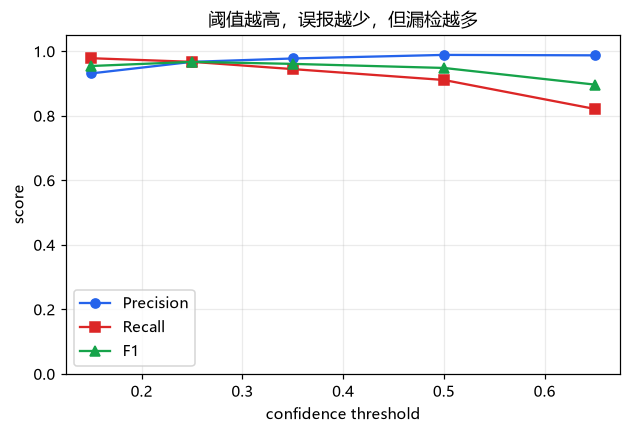

In [14]:
print("置信度阈值对指标的影响：")
rows = []
for conf in [0.15, 0.25, 0.35, 0.50, 0.65]:
    p, r, f1 = evaluate(conf_thres=conf, verbose=False)
    rows.append((conf, p, r, f1))
    print(f"conf={conf:.2f} | P={p:.3f} R={r:.3f} F1={f1:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
conf = [x[0] for x in rows]
ax.plot(conf, [x[1] for x in rows], "o-", label="Precision", color="#2563eb")
ax.plot(conf, [x[2] for x in rows], "s-", label="Recall", color="#dc2626")
ax.plot(conf, [x[3] for x in rows], "^-", label="F1", color="#16a34a")
ax.set_xlabel("confidence threshold")
ax.set_ylabel("score")
ax.set_ylim(0, 1.05)
ax.set_title("阈值越高，误报越少，但漏检越多")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 7.1 和 mAP 的关系

上面只算了某一个置信度阈值下的 P/R。把阈值从 0 扫到 1，就得到 PR 曲线；曲线下的面积就是 AP。验证集里只有 3 个类别，所以：

```text
mAP = (AP_red + AP_green + AP_blue) / 3
```

本 notebook 为了控制长度没有重复实现 AP（第 01 本已经实现过）。你可以把第 01 本的 `average_precision` 复制过来，对每个类别算 AP，得到真正的 mAP50。

## 8. 可视化：模型到底学到了什么？

绿色是 GT，橙色是预测。理想情况下，橙框应该和绿框几乎重合，并且类别、分数正确。

重点观察：

- 两个物体靠得很近时，是否都能检测到？
- 大物体和小物体的框质量有没有差别？
- 有没有“一个物体多个框”（NMS 没压干净）？
- 有没有漏检（FN）或背景误检（FP）？

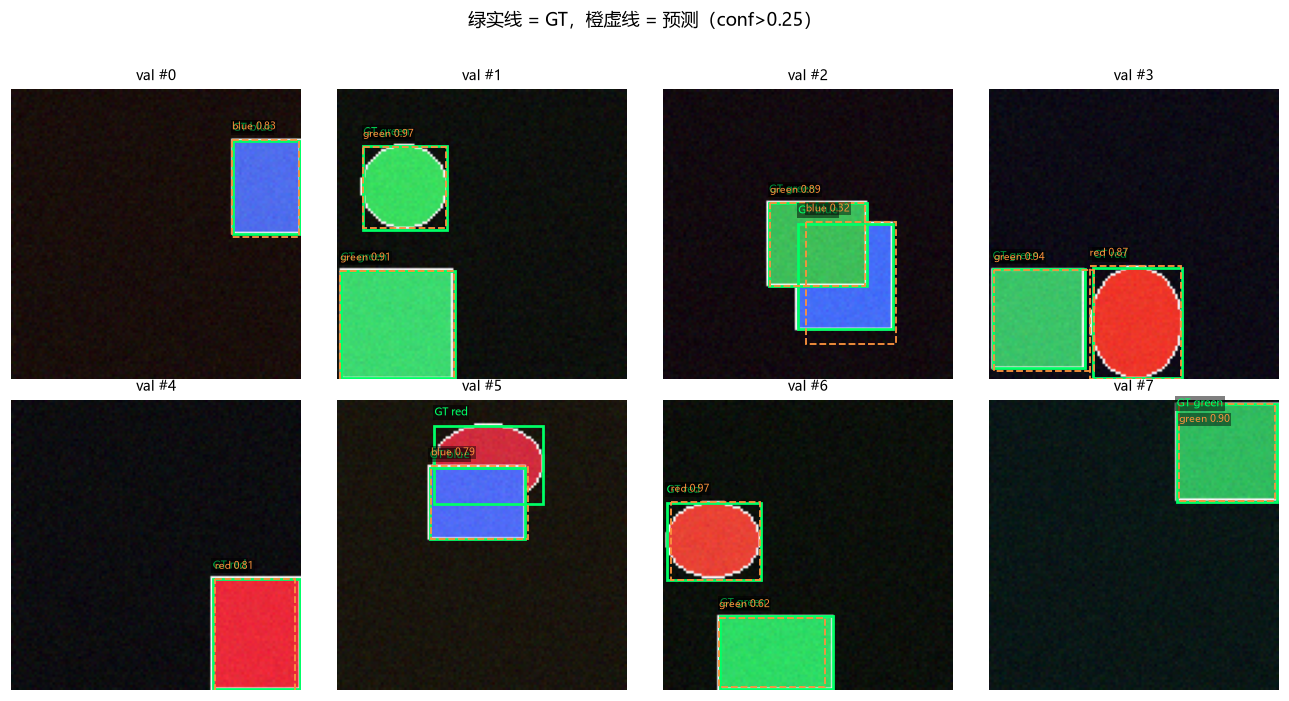

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for ax, i in zip(axes.ravel(), range(8)):
    ax.imshow(np.clip(val_images[i].permute(1, 2, 0).numpy(), 0, 1))
    gb = val_boxes[i]
    gxy = np.concatenate([gb[:, :2] - gb[:, 2:] / 2,
                          gb[:, :2] + gb[:, 2:] / 2], axis=1) * IMG_SIZE
    for box, label in zip(gxy, val_labels[i]):
        ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                       fill=False, edgecolor="#00ff66", lw=1.8))
        ax.text(box[0], max(box[1] - 4, 2), f"GT {CLASS_NAMES[label]}", color="#00ff66",
                fontsize=7, bbox=dict(facecolor="black", alpha=0.5, pad=1, edgecolor="none"))

    pb, pc, ps = preds_val[i]
    for box, cls, score in zip(pb, pc, ps):
        ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                       fill=False, edgecolor="#fb923c", lw=1.2, linestyle="--"))
        ax.text(box[0], max(box[1] - 4, 8), f"{CLASS_NAMES[cls]} {score:.2f}", color="#fb923c",
                fontsize=6.5, bbox=dict(facecolor="black", alpha=0.45, pad=0.8, edgecolor="none"))
    ax.axis("off")
    ax.set_title(f"val #{i}", fontsize=9)

plt.suptitle("绿实线 = GT，橙虚线 = 预测（conf>0.25）", y=1.02)
plt.tight_layout()
plt.show()

### 8.1 常见失败模式

| 现象 | 可能原因 | 可以试的修改 |
|---|---|---|
| 框都在图像中心 | 学成了“平均框”，定位 loss 没起作用 | 检查 `tx,ty` 是否正确加了格子偏移 |
| 一个物体很多框 | NMS 阈值太大 / 类别分数没乘 objectness | 降 `iou_thres`，检查 score 公式 |
| 全部预测成背景 | `noobj` 权重太大 / 正样本太少 | 降 `noobj`，检查 target 编码 |
| 类别全错 | 分类 loss 没乘 `obj` mask | 检查 `cls_loss` 的 mask |
| 训练 loss 降，验证很差 | 过拟合 / 数据太少 | 增强、增加数据、减小模型 |

这些问题在真实 YOLO 训练里同样会出现。区别只是现代 YOLO 用 BCE、CIoU、DFL、TAL 等更精细的部件。

## 9. 和真正的 YOLOv1 对照

| 项目 | 原版 YOLOv1 | 本 notebook |
|---|---|---|
| 输入 | `448×448` | `112×112` |
| 网格 | `7×7` | `7×7` |
| 每格框数 | 2 | 2 |
| 类别 | 20（VOC） | 3 |
| 输出 | `7×7×30` | `7×7×2×8` |
| 骨干 | 24 conv + 2 FC | 5 conv + 1×1 head |
| 激活 | LeakyReLU | SiLU |
| 框损失 | MSE + `sqrt(w,h)` | MSE |
| 分类/置信度 | MSE | MSE |
| 标签分配 | 当前预测中 IoU 最大的框 | 同左 |
| 后处理 | 阈值 + NMS | 同左 |

**没有变的东西**：单阶段、密集预测、格子负责中心点、objectness、端到端回归、NMS 后处理。这些是 YOLO 的“骨架”。

**变了的东西**：backbone、特征金字塔、anchor、标签分配、loss、数据增强。这些是 YOLOv2–v11 不断迭代的“血肉”。

## 10. 三句话总结

1. **YOLO 把检测变成密集回归**：每个格子直接预测“这里有没有物体、框在哪、是什么类”。
2. **训练的关键是目标分配**：只让中心点所在格子里 IoU 最大的框负责 GT，其余框学背景。
3. **推理的关键是解码 + NMS**：格子内偏移还原成绝对坐标，乘 objectness 得到类别分数，再压重复框。

### 练习

1. 把 `NUM_CLASSES` 改成 2，删掉蓝色类，重新生成数据并训练。输出张量的最后一维会变成多少？
2. 把 `BOXES_PER_CELL` 改成 1，观察两个物体靠得很近时的召回率。
3. 把 `coord` 从 5.0 改成 1.0，比较框的定位质量。
4. 把 `noobj` 从 0.5 改成 2.0，观察模型是否变得“保守”（预测框变少）。
5. 给数据加随机亮度变化，观察模型是否还能靠颜色分类。
6. 把 `conf_thres` 和 `iou_thres` 做成两个滑块（需要 `ipywidgets`），实时看检测结果。

> 下一本：`03_yolov8_inference.ipynb`。我们会加载真正的 YOLOv8n 预训练模型，拆开它的 `[1,84,8400]` 输出，看看现代 YOLO 和这个迷你版到底哪里不一样。